## **一、S6-01｜为什么先双流，再合流**

假设提示是「蓝色圆形」。冻结文本编码器提供关于 *蓝色* 和 *圆形* 的特征，带噪图像的 patch 则保存一部分颜色、边界和位置。主干需要决定两件事：图文各用什么参数整理自己的状态？它们什么时候可以读取彼此？这两个问题可以分开设计。以下正文先把设计和尺寸拆开，再通过合成图短训观察差异。

S5-02 的 Plain DiT 让图像状态读固定的文本特征。上一课的 Single-Stream DiT 从第一层就用同一套参数处理图文。**Hybrid DiT** 先让两个模态用各自的参数产生 Q、K、V 和 MLP 更新，但在注意力里互相读取。若干双流块之后，把最新的图文状态拼成一个序列，交给共享的单流块。图文信息在第一次 **联合注意力** 就开始交换，合流改变的是下一阶段使用的参数与计算图。

| 教学主干 | 文本是否在主干内更新 | 图像和文本如何通信 | 一层中参数如何使用 |
| --- | --- | --- | --- |
| Plain | 冻结条件特征供各层读取 | 图像自注意力和图像读文本的交叉注意力各自归一化 | 图像更新为主 |
| Stream | 每层更新有效文本状态 | 每层对拼接序列做联合注意力 | 图文共享 QKV、MLP 和时间调制 |
| Hybrid | 双流和单流阶段都更新有效文本状态 | 两个阶段都做联合注意力 | 前段按模态选择参数，后段共享参数 |

[上一课 Single-Stream DiT](S5_02_SingleStreamDiT架构与实现.ipynb) · [联合注意力和 2D RoPE](S5_01_JointAttention与2DRoPE.ipynb) · [课程路线](../MiniGen2学习目录.md)

### **1. 先把整条数据流走一遍**

训练时，图像经 VAE 编码为干净潜变量 $z$，与噪声构成中间状态 $z_t$。图像 token 来自 $z_t$ 的 patch；文本 token 来自冻结文本塔。Hybrid 处理两种状态，最后只把图像 token 投回潜空间，得到速度预测。采样时从纯噪声开始，在每个时间点重新执行同一主干，将速度积分为终点潜变量，再由 VAE 解码。冻结文本特征可以预先算好；联合层中的文本状态会随图像和时间改变。

```text
带噪潜变量 → patch 投影 → 图像状态 I ─┐
                                      ├→ 双流块 × D → 拼接 → 单流块 × S
冻结文本特征 → 文本投影 →  文本状态 T ─┘       ↕ 联合注意力          ↓
                                             分流更新         取图像 → 速度头 → 潜变量速度
```

### **2. 复用前课的冻结组件**

本课只在内存中重建几何图、冻结组件特征与留出探针。下方先加载固定身份的教学单元，后面再逐段读懂 Hybrid 代码。输入图示是几何样本与 VAE 重建。实验配置和生成图库分别在第六、八章。

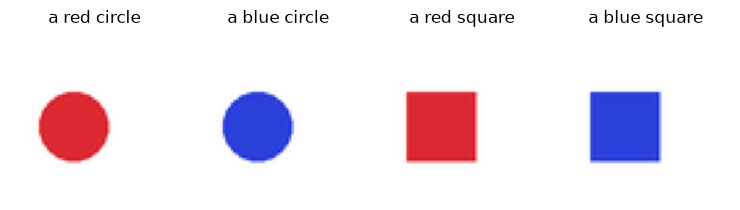

Python 3.12.14 | PyTorch 2.14.1 | CPU FP32
train=64 | val=32 | shared image hashes=0


/Users/lucius/projects/personal/MiniGen/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1107 15:42:03.519000 79487 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.



Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 196/196 [00:00<00:00, 30108.54it/s]

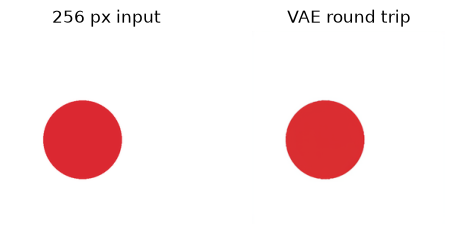

VAE revision=207b116dae70ace3637169f1ddd2434b91b3a8cd | scale=0.13025
CLIP revision=3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268 | valid tokens=[5, 5, 5, 5, 2]
256 latent=(1, 4, 32, 32); train latent=(64, 4, 8, 8)
text (5, 77, 512) -> (5, 5, 512); cache in RAM
train latent mean=0.2855 std=1.4042
components + cache: 5.75 s
256 probe patch tensor (1, 256, 16)
trainable DiT params = 609,714
held-out zero velocity MSE (mean of 3 times): 3.0672


In [1]:
import ast
import hashlib
import math
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import nbformat
import torch
from torch import Tensor, nn
from torch.nn import functional as F

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/models/sdxl_vae.json").is_file()
)
source = root / "docs/learning/S5_02_SingleStreamDiT架构与实现.ipynb"
previous = nbformat.read(source, as_version=4)
lesson = {}


def load_previous(tag: str, digest: str, only: tuple[str, ...] = ()) -> None:
    """校验前课单元源码。按标签执行单元，或仅载入指定定义。"""
    matches = [
        c.source
        for c in previous.cells
        if c.cell_type == "code" and tag in c.metadata.get("tags", ())
    ]
    if len(matches) != 1 or hashlib.sha256(matches[0].encode()).hexdigest() != digest:
        raise ValueError(f"S5-02 source identity mismatch: {tag}")
    tree = ast.parse(matches[0])
    if only:
        tree.body = [
            node
            for node in tree.body
            if isinstance(node, (ast.ClassDef, ast.FunctionDef)) and node.name in only
        ]
        if {node.name for node in tree.body} != set(only):
            raise ValueError(f"S5-02 definitions missing: {only}")
    exec(compile(tree, f"{source.name}:{tag}", "exec"), lesson)


load_previous("inputs", "70026f5d3aa34d089499770fd737818610ae444476b3ec42526573e1bf8f0d45")
load_previous("stream_block", "977abb5c69ebe79d89ced78639af9051a22fb64a17fd17feb3dbb141c397afd7")
load_previous(
    "model",
    "118cf3fbb2f08ca0604504a58984ca6933c86bd18505c1569f641c35e2fca338",
    ("SingleStreamDiTReference", "velocity", "fresh_model"),
)
load_previous("optimization", "3a96f86ef2337431143253d4653eec2cc2ebdfd4d9840f0fa867d76aa798e08c")
grid_coords, rotate_2d = lesson["grid_coords"], lesson["rotate_2d"]
patchify, unpatchify, sincos_1d = (
    lesson["patchify"],
    lesson["unpatchify"],
    lesson["sincos_1d"],
)
prev = lesson["prev"]
velocity, flow_example = lesson["velocity"], lesson["flow_example"]
step_batch, validation_rows = lesson["step_batch"], lesson["validation_rows"]
text_bank, mask_bank = lesson["text_bank"], lesson["mask_bank"]
val_z, val_y = lesson["val_z"], lesson["val_y"]
vae, captions = lesson["vae"], lesson["captions"]

## **二、读混元图像 2.1｜从系统到源码**

### **1. 系统中的三个层次**

混元图像 2.1 官方模型卡将发布系统分为 **基础文生图模型** 和 **后续图像 Refiner**。基础模型先从噪声生成图像潜变量，后续 Refiner 进一步细化结果。基础模型的约 17B DiT 本身已经包含双流和单流两个阶段。图文流的切换发生在一次 DiT 前向内部，和独立的图像精炼阶段属于两个层次。源码里还有一个名字相近的 `SingleTokenRefiner`，它在主干之前处理文本 token，职责也独立。官方前向将当前时间与文本掩码传入该模块，因此冻结文本编码器的特征可以复用，经过该模块后的文本状态仍依赖当前步。 [主干的文本处理入口](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/models/hunyuan/modules/hunyuanimage_dit.py#L391-L417) [官方模型卡与架构图](https://huggingface.co/tencent/HunyuanImage-2.1#text-to-image-model-architecture) · [官方中文说明](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/README_CN.md)

基础模型以 MLLM 提供场景、动作和长描述的语义特征，另用 ByT5 为文字渲染提供字形条件。ByT5 的输入单位是 UTF-8 字节，一个汉字通常占多个字节。官方管线为支持的引号内容构造字形条件和掩码，主干将有效 ByT5 token 与有效语义 token 排在 padding 前。官方权重指南将 Qwen2.5-VL-7B-Instruct 列为社区使用的替代文本编码器。要区分训练时描述的 MLLM 与发布推理可用的编码器。官方还报告了高压缩 VAE、利用 DINOv2 特征对齐的表示学习、DiT 的多分桶 REPA、SFT/RL 后训练和 MeanFlow 蒸馏。这些都是完整系统中的其他设计变量，不能从系统效果反推某一种 Block 的独立贡献。 [官方模型卡](https://huggingface.co/tencent/HunyuanImage-2.1#hunyuanimage-21-overall-pipeline) · [字形编码](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/diffusion/pipelines/hunyuanimage_pipeline.py#L328-L379) · [官方文本编码器下载说明](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/ckpts/checkpoints-download.md#downloading-textencoders) · [文本排序与输入路径](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/models/hunyuan/modules/hunyuanimage_dit.py#L273-L313)

[ByT5 论文第 2 节](https://arxiv.org/abs/2105.13626v3)

### **2. 先看发布配置，再看类的默认参数**

以下数值来自仓库发布配置 `hunyuanimage_v2_1_cfg`。不要从 `HYImageDiffusionTransformer` 的通用构造器默认值推断实际发布模型。

| 设计 | 混元图像 2.1 基础模型 | 本课 Hybrid |
| --- | --- | --- |
| 图像与 VAE | 以 2048×2048 为例，每个空间轴压缩 32 倍，64 个潜变量通道 | 短训 64×64，每轴压缩 8 倍，4 个潜变量通道 |
| latent patch | 1×1，例中 64×64 网格对应 4,096 个图像 token | 2×2，短训 4×4 网格对应 16 个图像 token |
| 宽度与注意力 | 3,584 宽，28 个头，每头 128 维 | 100 宽，5 个头，每头 20 维 |
| 双流与单流块数 | 20 + 40 | 1 + 1 |
| 位置和归一化 | 图像 Q/K 上的二维 RoPE，行列各 64 维，频率底数 256，QK RMSNorm | 图像 Q/K 上的二维 RoPE，行列各 10 维，频率底数 10,000，省略 QK RMSNorm |
| 文本条件与时间 | MLLM 文本细化和 ByT5 字形分支，蒸馏配置另有 guidance 与 MeanFlow 时间输入 | 冻结 CLIP 加线性投影，常规连续时间条件 |
| 联合序列和输出 | `[I;T]`，取图像前缀 | `[T;I]`，取图像后缀，延续 S5-02 |

2048 图像变成 $2048/32=64$ 个网格单元每边。对每个 1×1 patch 只产生一个 token，因此图像 token 数是 $64^2=4096$，与 64 个 **通道** 是两件事。这里算的是正方形实例，横纵尺寸改变时分别计算。官方 Refiner 有自己的配置，输入输出通道和 RoPE 切分也不同。 [发布配置](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/models/hunyuan/configs/hunyuanimage_config.py#L7-L49) · [位置与归一化入口](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/models/hunyuan/modules/hunyuanimage_dit.py#L104-L177)

### **3. 按这条路径读官方代码和论文**

| 想回答的问题 | 对照材料 | 阅读动作 |
| --- | --- | --- |
| 双流怎样共享注意力？ | [官方联合注意力](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/models/hunyuan/modules/models.py#L16-L52) · [双流块](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/models/hunyuan/modules/models.py#L138-L230) | 跟踪两套 QKV 拼接成一次注意力，再找各自的输出投影、残差和 FFN |
| 合流后，注意力先于 MLP 吗？ | [官方单流块](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/models/hunyuan/modules/models.py#L232-L334) | 找出共用的归一化输入、两支并行计算和最后的门控 |
| 何处第一次持久拼接，如何读回图像？ | [官方主干前向](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/models/hunyuan/modules/hunyuanimage_dit.py#L389-L469) | 从两个 block 循环追到图像前缀、时间调制输出头与反 patch |
| 模态独立参数、联合注意力的早期依据？ | [SD3 论文第 4 节与图 2(b)](https://arxiv.org/html/2403.03206v1#S4) | 比较普通文本交叉注意力和 MMDiT 的双向联合注意力 |
| 同家族如何解释双流后合流？ | [HunyuanVideo 论文第 4.2 节、图 8、表 2](https://arxiv.org/html/2412.03603v6#S4.SS2) | 读阶段切换和三维 RoPE，参数表属于视频模型 |
| 官方模型卡附的论文讲什么？ | [PromptEnhancer](https://arxiv.org/abs/2509.04545v5) | 读提示词改写和奖励信号，2.1 主干实现以发布配置与源码为准 |

同名系列容易混用。2024 年的 [Hunyuan-DiT 技术报告](https://arxiv.org/abs/2405.08748) 和 [HunyuanImage 3.0 技术报告](https://arxiv.org/abs/2509.23951v2) 分别描述其他版本。课程目录里的 Chimera 也使用 “hybrid” 一词，指同一序列中组合 Kimi Delta Attention 与 Multi-head Latent Attention 等算子；本课的 Hybrid 指前后阶段对模态参数采用不同共享方式，两个阶段都使用联合注意力。资料核对日期为 2026-11-07。 [Chimera 论文](https://arxiv.org/abs/2607.28611v1)

## **三、双流块｜先独立投影，再共用一个 softmax**

### **1. 两套参数看到同一个时间**

设 $T\in\mathbb R^{b\times n_t\times d}$ 与 $I\in\mathbb R^{b\times n_i\times d}$。每个样本的时间向量 $e\in\mathbb R^d$ 进入两个不同的调制投影。对模态 $m\in\{T,I\}$，投影产生注意力和 MLP 各一组平移 $s$、缩放 $\gamma$ 与残差门 $g$。以注意力分支为例：

$$U_m=\operatorname{LN}(X_m)\odot(1+\gamma^a_m)+s^a_m,\qquad (Q_m,K_m,V_m)=U_m W_m^{qkv}+b_m^{qkv}.$$

调制逐样本、逐通道，在序列轴广播。$T$ 与 $I$ 的线性层独立，所以即使接受同一个 $e$，也可以分别学出「当前噪声水平下，图像该怎么读信息」和「文本该怎么调整表示」。这是一种容量分配的设计动机，效果要靠实验判断。

### **2. 图文打分矩阵的四个象限**

多头拆分后，每个头宽度为 $d_h=d/a$，其中 $a$ 是头数。2D RoPE 仅旋转图像 Q/K。按本课的文本在前顺序把每种投影沿序列轴拼接。忽略 batch 和头维写出一次打分：

$$L=\frac{1}{\sqrt{d_h}}\begin{bmatrix}Q_TK_T^\top&Q_TK_I^\top\\Q_IK_T^\top&Q_IK_I^\top\end{bmatrix}+M,\qquad A=\operatorname{softmax}_{\mathrm{key}}(L)\begin{bmatrix}V_T\\V_I\end{bmatrix}.$$

行是查询，列是键。右上角说明 **文本读图像**，左下角说明 **图像读文本**。$M$ 把无效文本键的 logits 设为 $-\infty$。对某一条查询只有一个归一化分母，其中包含 **所有有效的图文键**。例如把已缩放的分数设为两个文本键 $(0,\ln 2)$ 和一个图像键 $\ln 3$。第二个文本键是 padding，于是分母为 $e^0+e^{\ln 3}=4$，权重为 $(1/4,0,3/4)$。若三条值向量在某通道分别为 $2,99,6$，输出为 $2/4+18/4=5$。两边各自做 softmax 再相加，就失去这个跨模态竞争关系。

### **3. 沿查询边界切回两个流**

$A$ 的行仍和 Q 同序。我们把头拼回 $d$，再按 $(n_t,n_i)$ 拆出 $A_T,A_I$，分别应用各自的输出投影和门控。注意这里的 $n_t$ 是批内填充后的 **槽位数**。掩码来自逐槽位的布尔有效性，分流和裁切则沿固定的张量边界。两个样本即使有效文本数相同，有效位置也可能不同。

$$X'_m=X_m+g^a_m\odot W_m^o(A_m),\qquad X''_m=X'_m+g^f_m\odot\operatorname{MLP}_m\!\big(\operatorname{LN}(X'_m)\odot(1+\gamma^f_m)+s^f_m\big).$$

式中的 $W_m^o(A_m)$ 代表含偏置的输出线性层。这里先加注意力残差，再从更新后的状态计算 MLP。有效图像键始终存在，哪怕文本都被遮住也有合法 softmax 行。教学 SDPA 使用 `True=键可见`。padding 查询即使算过，也在回写时归零。官方实现则用 image-first 的掩码和去 padding 的 FlashAttention，且将 `causal=False` 传给联合层。 [官方注意力及双流实现](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/models/hunyuan/modules/models.py#L16-L230)

## **四、并行单流｜共享输入、共享门、只输出图像**

### **1. 跟踪两支的输入到底来自哪里**

双流结束时拼接 $X=[T;I]$，拼的是已经更新过的两组状态。混元图像 2.1 的单流块把一个归一化、调制后的 $U$ 同时交给共享 QKV 与 MLP 输入层。令 $r=4$ 为 MLP 扩展比，注意力输出 $A$ 每个 token 有 $d$ 维，MLP 中间量 $H$ 每个 token 有 $rd$ 维：

$$U=\operatorname{LN}(X)\odot(1+\gamma)+s,\qquad A=\operatorname{JointAttention}\big(Q(U),K(U),V(U)\big),\qquad H=\operatorname{GELU}(U W_f+b_f).$$

$$X_{\mathrm{out}}=X+g\odot\big([A,H]_{\mathrm{feature}}W_o+b_o\big).$$

第一次拼接 `[T;I]` 沿 **序列轴**，增多 token。第二次拼接 `[A,H]` 沿 **特征轴**，每个 token 从 $d$ 和 $4d$ 合成 $5d$，token 数保持不变。共享输出层把 $5d$ 投回 $d$，再经同一个门写入残差。按行向量记法，把 $W_o$ 沿输入特征拆成 $W_a\in\mathbb R^{d\times d}$ 和 $W_h\in\mathbb R^{4d\times d}$，就得到 $A W_a+H W_h+b_o$。这里两个项具有相同的 token 数和输出宽度，偏置只加一次。两支都读 $U$，因此不会像双流块的各模态分支或 S5-02 的共享串行块那样，让 MLP 读取注意力残差更新后的状态。 [官方单流实现](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/models/hunyuan/modules/models.py#L232-L334)

看源码时，官方块从同一个 $U$ 分别计算 `linear1_q/k/v/mlp`；本课用一个 `Linear(d,7d)`，再切成 $d+d+d+4d$。把分开的仿射层沿输出维堆起来，就得到这一个大投影。两支怎样依赖 $U$ 与权重是否放在同一个张量里是两件事。 [官方单流实现](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/models/hunyuan/modules/models.py#L256-L333)

### **2. 从序列切回潜变量网格**

教学模型的 `[T;I]` 顺序贯穿两阶段：拼接时文本在前，RoPE 定位到图像后缀，掩码把相同范围标为文本，最终切 `tokens[:, n_text:]`。例如 64px 图像有 16 个图像 token，空提示只有两个有效特殊 token，却仍占五个文本槽。拼接序列长 21，图像从索引 5 开始。若切在 2，会把三个 padding 当成图像。若读混元源码，顺序反过来，最后切 `x[:, :img_seq_len]`。

| 节点 | 64px 短训 | 256px 前向探针 |
| --- | --- | --- |
| VAE 缩放潜变量 | `[b,4,8,8]` | `[b,4,32,32]` |
| 2×2 patch 展平并投影 | `[b,16,16]` → `[b,16,100]` | `[b,256,16]` → `[b,256,100]` |
| CLIP 特征和文本投影 | `[b,5,512]` → `[b,5,100]` | `[b,77,512]` → `[b,77,100]` |
| 拆头后的每个 Q/K/V 张量 | `[b,5,21,20]` | `[b,5,333,20]` |
| 合流后的注意力与 MLP 特征拼接 | `[b,21,500]` | `[b,333,500]` |
| 切图像、输出头、逆 patch | `[b,4,8,8]` | `[b,4,32,32]` |

最后的图像 token 经时间调制和线性层变成每 patch 的 $4\times2^2=16$ 个速度分量。逆 patch 恢复空间排列。尽管速度头只读图像，训练梯度仍可经过联合注意力传回文本分支。接下来分别检查「张量走对」和「这条路确实有梯度」。

## **五、把公式接到 PyTorch，再做主动验证**

### **1. 双流和联合注意力的参考实现**

`ModalityBranch` 提供每个模态独立的 `project` 和 `update`。`joint_qkv` 负责头维变换与 RoPE，`joint_attention` 只负责一次共享的 SDPA 和头维还原。`DoubleStreamBlockReference` 是两边的调度者：按顺序拼接投影、按查询边界拆开结果、交回自己的分支更新。

In [2]:
def modulate_tokens(tokens: Tensor, shift: Tensor, scale: Tensor) -> Tensor:
    """将每个样本的时间调制广播到该样本的所有 Token。"""
    return tokens * (1 + scale[:, None]) + shift[:, None]


def joint_valid(text_valid: Tensor, image: Tensor) -> Tensor:
    """按 [文本；图像] 排列有效键，所有图像 patch 有效。"""
    return torch.cat((text_valid, torch.ones_like(image[..., 0], dtype=torch.bool)), dim=1)


def joint_qkv(
    packed: Tensor, heads: int, n_text: int, coords: Tensor
) -> tuple[Tensor, Tensor, Tensor]:
    """将 [b,n,3d] 拆为三个 [b,a,n,d_h]，仅旋转图像 Q/K。"""
    b, n, three_d = packed.shape
    q, k, v = packed.reshape(b, n, 3, heads, three_d // (3 * heads)).permute(2, 0, 3, 1, 4)
    q = torch.cat((q[:, :, :n_text], rotate_2d(q[:, :, n_text:], coords)), dim=2)
    k = torch.cat((k[:, :, :n_text], rotate_2d(k[:, :, n_text:], coords)), dim=2)
    return q, k, v


def joint_attention(
    packed: Tensor, heads: int, n_text: int, coords: Tensor, valid: Tensor
) -> Tensor:
    """一次 softmax 覆盖所有有效图文键，结果恢复为 [b,n,d]。"""
    q, k, v = joint_qkv(packed, heads, n_text, coords)
    result = F.scaled_dot_product_attention(q, k, v, attn_mask=valid[:, None, None, :])
    return result.transpose(1, 2).flatten(2)


class ModalityBranch(nn.Module):
    """双流块中一个模态的时间调制、投影和残差更新。"""

    def __init__(self, width: int) -> None:
        super().__init__()
        self.norm_attention = nn.LayerNorm(width, elementwise_affine=False, eps=1e-6)
        self.norm_mlp = nn.LayerNorm(width, elementwise_affine=False, eps=1e-6)
        self.modulation = nn.Sequential(nn.SiLU(), nn.Linear(width, 6 * width))
        self.qkv = nn.Linear(width, 3 * width)
        self.proj = nn.Linear(width, width)
        self.mlp = nn.Sequential(
            nn.Linear(width, 4 * width), nn.GELU(approximate="tanh"), nn.Linear(4 * width, width)
        )

    def project(
        self, tokens: Tensor, time: Tensor
    ) -> tuple[Tensor, tuple[Tensor, Tensor, Tensor, Tensor]]:
        """分别得到本模态的 QKV 和两条残差更新所需的时间参数。"""
        shift_a, scale_a, gate_a, shift_m, scale_m, gate_m = self.modulation(time).chunk(6, dim=-1)
        packed = self.qkv(modulate_tokens(self.norm_attention(tokens), shift_a, scale_a))
        return packed, (gate_a, shift_m, scale_m, gate_m)

    def update(
        self, tokens: Tensor, attended: Tensor, modulation: tuple[Tensor, Tensor, Tensor, Tensor]
    ) -> Tensor:
        """只把联合注意力中本模态的查询结果写回本模态。"""
        gate_a, shift_m, scale_m, gate_m = modulation
        tokens = tokens + gate_a[:, None] * self.proj(attended)
        return tokens + gate_m[:, None] * self.mlp(
            modulate_tokens(self.norm_mlp(tokens), shift_m, scale_m)
        )


class DoubleStreamBlockReference(nn.Module):
    """各模态有独立参数，在一次联合注意力里双向交换信息。"""

    def __init__(self, width: int, heads: int) -> None:
        super().__init__()
        self.heads = heads
        self.image = ModalityBranch(width)
        self.caption = ModalityBranch(width)

    def forward(
        self, image: Tensor, caption: Tensor, time: Tensor, text_valid: Tensor, coords: Tensor
    ) -> tuple[Tensor, Tensor]:
        n_text = caption.shape[1]
        image_qkv, image_mod = self.image.project(image, time)
        text_qkv, text_mod = self.caption.project(caption, time)
        attended = joint_attention(
            torch.cat((text_qkv, image_qkv), dim=1),
            self.heads,
            n_text,
            coords,
            joint_valid(text_valid, image),
        )
        new_image = self.image.update(image, attended[:, n_text:], image_mod)
        new_text = self.caption.update(caption, attended[:, :n_text], text_mod)
        return new_image, new_text.masked_fill(~text_valid[..., None], 0.0)

### **2. 并行单流与整网输出**

并行块用一层 `linear_in` 一次得到 $3d+4d$ 个特征，前 $3d$ 给 QKV，剩余给 GELU。`linear_out` 对应上文的 $5d\to d$。完整模型沿用 S5-02 的入口约定。时间仍在 $[0,1]$ 内采样和积分，传到时间嵌入前才乘 1000。`prepare` 里的坐标直接来自图像网格，和前面有多少文本槽无关。

In [3]:
class ParallelSingleStreamBlockReference(nn.Module):
    """合流后，共享同一份归一化输入，并行计算注意力与 MLP 分支。"""

    def __init__(self, width: int, heads: int) -> None:
        super().__init__()
        self.width, self.heads = width, heads
        self.norm = nn.LayerNorm(width, elementwise_affine=False, eps=1e-6)
        self.modulation = nn.Sequential(nn.SiLU(), nn.Linear(width, 3 * width))
        self.linear_in = nn.Linear(width, 7 * width)
        self.linear_out = nn.Linear(5 * width, width)

    def forward(
        self, tokens: Tensor, time: Tensor, valid: Tensor, n_text: int, coords: Tensor
    ) -> Tensor:
        shift, scale, gate = self.modulation(time).chunk(3, dim=-1)
        modulated = modulate_tokens(self.norm(tokens), shift, scale)
        packed, mlp_in = self.linear_in(modulated).split((3 * self.width, 4 * self.width), dim=-1)
        attended = joint_attention(packed, self.heads, n_text, coords, valid)
        features = torch.cat((attended, F.gelu(mlp_in, approximate="tanh")), dim=-1)
        tokens = tokens + gate[:, None] * self.linear_out(features)
        return tokens.masked_fill(~valid[..., None], 0.0)

In [4]:
class HybridDiTReference(nn.Module):
    """先分支更新，再合并为共享序列，最终只输出图像潜空间速度。"""

    double_block_type = DoubleStreamBlockReference
    single_block_type = ParallelSingleStreamBlockReference

    def __init__(
        self,
        width: int = 100,
        heads: int = 5,
        dual_depth: int = 1,
        single_depth: int = 1,
        patch: int = 2,
        channels: int = 4,
        text_width: int = 512,
    ) -> None:
        super().__init__()
        if heads <= 0 or width <= 0 or width % (4 * heads):
            raise ValueError("head width must be a positive multiple of four")
        if min(patch, channels, text_width) <= 0 or min(dual_depth, single_depth) < 0:
            raise ValueError("expected positive dimensions and nonnegative block counts")
        self.width, self.patch, self.channels = width, patch, channels
        patch_width = patch**2 * channels
        self.image_in = nn.Linear(patch_width, width)
        self.text_in = nn.Linear(text_width, width)
        self.modality = nn.Parameter(torch.zeros(2, width))
        self.time_mlp = nn.Sequential(nn.Linear(width, width), nn.SiLU(), nn.Linear(width, width))
        self.dual_blocks = nn.ModuleList(
            self.double_block_type(width, heads) for _ in range(dual_depth)
        )
        self.single_blocks = nn.ModuleList(
            self.single_block_type(width, heads) for _ in range(single_depth)
        )
        self.final_norm = nn.LayerNorm(width, elementwise_affine=False, eps=1e-6)
        self.final_mod = nn.Sequential(nn.SiLU(), nn.Linear(width, 2 * width))
        self.output = nn.Linear(width, patch_width)
        for layer in self.modules():
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)
        zero_layers = [
            *(
                branch.modulation[-1]
                for block in self.dual_blocks
                for branch in (block.image, block.caption)
            ),
            *(block.modulation[-1] for block in self.single_blocks),
            self.final_mod[-1],
            self.output,
        ]
        for layer in zero_layers:
            nn.init.zeros_(layer.weight)
            nn.init.zeros_(layer.bias)

    def prepare(
        self, z: Tensor, feature_time: Tensor, text: Tensor, text_valid: Tensor
    ) -> tuple[Tensor, Tensor, Tensor, Tensor]:
        """投影图像和文本，并准备时间条件及独立于文本长度的图像坐标。"""
        b, c, h, w = z.shape
        if c != self.channels or not h or not w or h % self.patch or w % self.patch:
            raise ValueError("latent must have the configured channels and divisible h,w")
        if text.ndim != 3 or text.shape[:2] != text_valid.shape or text_valid.dtype != torch.bool:
            raise ValueError("expected matching text features and boolean mask")
        if len(text) != b or feature_time.shape != (b,):
            raise ValueError("text and time batch must match latent")
        image = self.image_in(patchify(z, self.patch)) + self.modality[1]
        caption = (self.text_in(text) + self.modality[0]).masked_fill(~text_valid[..., None], 0.0)
        time = self.time_mlp(sincos_1d(feature_time, self.width).to(z.dtype))
        coords = grid_coords(h // self.patch, w // self.patch).to(z.device)
        return image, caption, time, coords

    def forward(self, z: Tensor, feature_time: Tensor, text: Tensor, text_valid: Tensor) -> Tensor:
        _, c, h, w = z.shape
        image, caption, time, coords = self.prepare(z, feature_time, text, text_valid)
        for block in self.dual_blocks:
            image, caption = block(image, caption, time, text_valid, coords)
        n_text = caption.shape[1]
        tokens = torch.cat((caption, image), dim=1)
        valid = joint_valid(text_valid, image)
        for block in self.single_blocks:
            tokens = block(tokens, time, valid, n_text, coords)
        shift, scale = self.final_mod(time).chunk(2, dim=-1)
        image = modulate_tokens(self.final_norm(tokens[:, n_text:]), shift, scale)
        return unpatchify(self.output(image), c, h, w, self.patch)

时间调制末层和图像输出头零初始化。有效 token 的残差块初始是恒等映射，整网初始速度为零。沿用行向量记法，$y=hW_{\mathrm{out}}+b_{\mathrm{out}}$ 给出 $\partial L/\partial h=(\partial L/\partial y)W_{\mathrm{out}}^\top$，所以第一步更适合检查输出头梯度。要检查早期分支，应人为打开门做数值对照，或用经过更新的模型做梯度探针。

### **3. 给错误的实现一个能失败的算例**

- 双流：用 FP64 小张量，开启两个模态的注意力和 MLP 门。显式写出点积、唯一的 softmax 与手算旋转矩阵，复算两边的残差。分别从图像输出反传到文本、从文本输出反传到图像，验证双向路径以及无效文本零梯度。
- 单流：将融合线性层按权重切片拆开，用显式 GELU 对照并行公式，检查两支的输出如何经同一个门写回。
- 整网：用两种记录调用的替身块注入不同变化，检查阶段顺序、文本槽位、坐标、时间条件、图像切片和反 patch。用非零输出头暴露切错序列边界的错误。

In [5]:
def manual_joint_two_patches(qkv: Tensor, valid: Tensor) -> Tensor:
    """独立算例固定 2 个文本槽、2 个图像 patch、2 个头和 4 维头宽。"""
    b = qkv.shape[0]
    q, k, v = (part.reshape(b, 4, 2, 4).transpose(1, 2) for part in qkv.split(8, dim=-1))
    # 图像坐标为 (0,0) 和 (0,1)。只有末 Token 的列分量需要旋转 1 弧度。
    rotation = torch.eye(4, dtype=qkv.dtype)
    rotation[2:, 2:] = qkv.new_tensor([[math.cos(1), math.sin(1)], [-math.sin(1), math.cos(1)]])
    q = torch.cat((q[:, :, :3], q[:, :, 3:] @ rotation), dim=2)
    k = torch.cat((k[:, :, :3], k[:, :, 3:] @ rotation), dim=2)
    logits = (q @ k.transpose(-2, -1)) / 2
    weights = logits.masked_fill(~valid[:, None, None], -torch.inf).softmax(-1)
    return (weights @ v).transpose(1, 2).reshape(b, 4, 8)


def audit_double_stream(block_type: type[DoubleStreamBlockReference]) -> None:
    """开启两个模态的注意力和 MLP 门，与显式 softmax/两条残差对照。"""
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(60101)
        block = block_type(8, 2).double()
    rng = torch.Generator().manual_seed(60103)
    image = torch.randn(1, 2, 8, dtype=torch.float64, generator=rng, requires_grad=True)
    text = torch.randn(1, 2, 8, dtype=torch.float64, generator=rng, requires_grad=True)
    time = torch.randn(1, 8, dtype=torch.float64, generator=rng)
    mask = torch.tensor([[True, False]])
    valid = torch.tensor([[True, False, True, True]])
    coords = torch.tensor([[0, 0], [0, 1]])

    with torch.no_grad():
        # 两个分支参数本来独立，再明确把所有门偏置设为非零。
        block.image.modulation[-1].bias[16:24] = 0.8
        block.image.modulation[-1].bias[40:48] = 0.7
        block.caption.modulation[-1].bias[16:24] = -0.5
        block.caption.modulation[-1].bias[40:48] = 0.9
        im = block.image.modulation(time).reshape(1, 6, 1, 8).unbind(dim=1)
        txt = block.caption.modulation(time).reshape(1, 6, 1, 8).unbind(dim=1)
        iqkv = block.image.qkv(F.layer_norm(image, (8,), eps=1e-6) * (1 + im[1]) + im[0])
        tqkv = block.caption.qkv(F.layer_norm(text, (8,), eps=1e-6) * (1 + txt[1]) + txt[0])
        text_read, image_read = manual_joint_two_patches(
            torch.cat((tqkv, iqkv), dim=1), valid
        ).split(2, dim=1)
        image_mid = image + im[2] * block.image.proj(image_read)
        text_mid = text + txt[2] * block.caption.proj(text_read)
        expected_image = image_mid + im[5] * block.image.mlp(
            F.layer_norm(image_mid, (8,), eps=1e-6) * (1 + im[4]) + im[3]
        )
        expected_text = text_mid + txt[5] * block.caption.mlp(
            F.layer_norm(text_mid, (8,), eps=1e-6) * (1 + txt[4]) + txt[3]
        )
        expected_text = torch.where(mask[..., None], expected_text, 0.0)
    actual_image, actual_text = block(image, text, time, mask, coords)
    torch.testing.assert_close(actual_image, expected_image, rtol=1e-10, atol=1e-10)
    torch.testing.assert_close(actual_text, expected_text, rtol=1e-10, atol=1e-10)
    # 分开反传两个输出，验证注意力在双流阶段已经建立双向路径。
    g_text = torch.autograd.grad(actual_image.square().sum(), text, retain_graph=True)[0]
    g_image = torch.autograd.grad(actual_text.square().sum(), image)[0]
    assert torch.isfinite(g_text).all() and torch.isfinite(g_image).all()
    assert g_image.norm() > 1e-5 and g_text[mask].norm() > 1e-5
    assert torch.count_nonzero(g_text[~mask]) == 0


def audit_parallel_single(block_type: type[ParallelSingleStreamBlockReference]) -> None:
    """分别展开 QKV 和 MLP 线性切片，核对合流块的并行残差。"""
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(60105)
        block = block_type(8, 2).double()
    rng = torch.Generator().manual_seed(60107)
    tokens = torch.randn(1, 4, 8, dtype=torch.float64, generator=rng)
    time = torch.randn(1, 8, dtype=torch.float64, generator=rng)
    valid = torch.tensor([[True, False, True, True]])
    coords = torch.tensor([[0, 0], [0, 1]])
    with torch.no_grad():
        block.modulation[-1].bias[16:] = 0.6
        shift, scale, gate = block.modulation(time).reshape(1, 3, 1, 8).unbind(dim=1)
        source = F.layer_norm(tokens, (8,), eps=1e-6) * (1 + scale) + shift
        qkv = F.linear(source, block.linear_in.weight[:24], block.linear_in.bias[:24])
        mlp = F.linear(source, block.linear_in.weight[24:], block.linear_in.bias[24:])
        activated = 0.5 * mlp * (1 + torch.tanh(math.sqrt(2 / math.pi) * (mlp + 0.044715 * mlp**3)))
        read = manual_joint_two_patches(qkv, valid)
        merged = F.linear(read, block.linear_out.weight[:, :8], block.linear_out.bias)
        merged = merged + F.linear(activated, block.linear_out.weight[:, 8:])
        expected = torch.where(valid[..., None], tokens + gate * merged, 0.0)
    actual = block(tokens, time, valid, 2, coords)
    torch.testing.assert_close(actual, expected, rtol=1e-10, atol=1e-10)


def audit_hybrid_routing(model_type: type[HybridDiTReference]) -> None:
    """让两个阶段留下不同的更新，检验掩码、调用顺序、切片和逆 patch。"""
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(60109)
        model = model_type(width=8, heads=2, dual_depth=0, single_depth=0, text_width=3).double()
    dual_delta = torch.arange(8, dtype=torch.float64) / 8
    single_delta = torch.flip(dual_delta, dims=(0,)).square()

    class TraceDouble(nn.Module):
        def forward(
            self, image: Tensor, caption: Tensor, time: Tensor, mask: Tensor, coords: Tensor
        ) -> tuple[Tensor, Tensor]:
            self.record = image, caption, time, mask, coords
            return image + dual_delta, (caption - dual_delta).masked_fill(~mask[..., None], 0.0)

    class TraceSingle(nn.Module):
        def forward(
            self, tokens: Tensor, time: Tensor, valid: Tensor, n_text: int, coords: Tensor
        ) -> Tensor:
            self.record = tokens, time, valid, n_text, coords
            return tokens + single_delta

    dual, single = TraceDouble(), TraceSingle()
    model.dual_blocks.append(dual)
    model.single_blocks.append(single)
    with torch.no_grad():
        model.output.weight.copy_(torch.eye(16, 8, dtype=torch.float64))
        z = torch.arange(64, dtype=torch.float64).reshape(1, 4, 4, 4) / 32
        t = torch.tensor([200.0], dtype=z.dtype)
        text = torch.tensor([[[0.2, 0.4, -0.2], [20.0, 90.0, 15.0]]], dtype=z.dtype)
        mask = torch.tensor([[True, False]])
        actual = model(z, t, text, mask)
        image, caption, time, received_mask, coords = dual.record
        combined, second_time, valid, n_text, second_coords = single.record
        assert n_text == 2
        torch.testing.assert_close(received_mask, mask)
        torch.testing.assert_close(valid, torch.tensor([[True, False, True, True, True, True]]))
        torch.testing.assert_close(coords, torch.tensor([[0, 0], [0, 1], [1, 0], [1, 1]]))
        torch.testing.assert_close(second_coords, coords)
        torch.testing.assert_close(second_time, time)
        torch.testing.assert_close(time, model.time_mlp(sincos_1d(t, 8).to(z.dtype)))
        torch.testing.assert_close(image, model.image_in(patchify(z, 2)) + model.modality[1])
        expected_caption = (model.text_in(text) + model.modality[0]).masked_fill(
            ~mask[..., None], 0.0
        )
        torch.testing.assert_close(caption, expected_caption)
        torch.testing.assert_close(
            combined[:, :2], (caption - dual_delta).masked_fill(~mask[..., None], 0.0)
        )
        torch.testing.assert_close(combined[:, 2:], image + dual_delta)
        image_features = model.final_norm(image + dual_delta + single_delta)
        expected = unpatchify(model.output(image_features), 4, 4, 4, 2)
        torch.testing.assert_close(actual, expected)
        assert actual.abs().max() > 0


audit_double_stream(DoubleStreamBlockReference)
audit_parallel_single(ParallelSingleStreamBlockReference)
audit_hybrid_routing(HybridDiTReference)
print("双流显式数值、双向梯度、合流并行残差、图像切片与逆 patch 均通过")

双流显式数值、双向梯度、合流并行残差、图像切片与逆 patch 均通过


## **六、参数量、算量与对照条件**

### **1. 多一套参数，为什么不等于每个 token 算两遍**

先只数本课的线性层，取宽度 $d$、MLP 比例 4、带偏置、无仿射 LayerNorm、无 QK RMSNorm。每个模态分支拥有 QKV 与输出投影 $4d^2+4d$、MLP $8d^2+5d$、六向量调制 $6d^2+6d$。因此双流块有：

$$P_{\mathrm{dual}}=2[(4d^2+4d)+(8d^2+5d)+(6d^2+6d)]=36d^2+30d.$$

并行单流的三项是 `linear_in` 的 $7d^2+7d$、`linear_out` 的 $5d^2+d$，以及三向量调制的 $3d^2+3d$，所以 $P_{\mathrm{parallel}}=15d^2+11d$。输入输出头、模态向量和时间 MLP 在本课固定通道、patch 与 CLIP 宽度时合计 $4d^2+552d+16$。代入 $d=100$ 和 1+1 层，$363{,}000+151{,}100+95{,}216=609{,}316$。

对 $n=n_t+n_i$ 个 token，双流的图像层处理 $n_i$ 个、文本层处理 $n_t$ 个。两边每个 token 的主线性层各约 $12d^2$ 次乘加，合计仍是 $12nd^2$。并行单流也有 $7nd^2+5nd^2=12nd^2$。两者稠密注意力的 QK 与加权求和另约 $2n^2d$ 次乘加。这些式子按单样本前向、忽略偏置、归一化、激活、时间调制和读写。显存、反传、参数状态、内核是否去 padding、访存和硬件吞吐都影响实际成本，不能用这条估算替代实测。

例如在本课公式下，$d=384$、8 头、3 双流加 6 并行单流约 30.1M 参数。这个数能帮助筛配置，最终还要核对真实模块、参数规模、训练 FLOPs 和显存。正式 B2 需要在 OpenClipart 和统一训练协议下验收，本课的约 0.61M 模型用来理解结构与实验。

### **2. 固定教学配方，明确还剩哪些变量**

| 条件 | 这次如何控制 |
| --- | --- |
| 数据 | 64 张训练、32 张留出，红蓝 × 圆方，按几何场景隔离，四类语义在两边都出现 |
| 组件 | 同一冻结 SDXL VAE 与 CLIP，后验均值编码和固定缩放，64px 数据及缓存只在内存 |
| 训练 | 种子 50211、50212，每个种子下三模型从各自初始化开始，共用每步 16 个样本、噪声、时间和以 10% 概率丢弃整条条件的结果 |
| 优化 | CPU FP32，AdamW 学习率 0.0003、权重衰减 0.01，梯度范数上限 1，固定 1,600 次更新，最后一步作为结果 |
| 配置 | Plain 2 层、96 宽、4 头；Stream 2 层、120 宽、5 头；Hybrid 1+1 层、100 宽、5 头 |
| 仍会变化 | 注意力路由、位置编码、头宽、参数量、单流是否并行及计算开销 |

Plain 与 Stream 使用上课经过身份校验的教学定义；本课从头跑三组，不把历史权重接到 Hybrid。输入单元只读取之前固定标签的代码，重建教学图、冻结特征与留出探针，不写回旧 Notebook。冻结权重按前课固定版本离线读取。可在项目根目录用现有环境复跑，执行器会写回当前 Notebook 的输出。

```bash
HF_HUB_OFFLINE=1 TRANSFORMERS_OFFLINE=1 .venv/bin/python scripts/execute_learning.py \
  docs/learning/S6_01_HybridDiT双流单流架构.ipynb \
  --html-output artifacts/learning/s6_01/learning_preview.html
```

### **3. 速度监督与反事实探针**

沿用噪声到数据的线性路径。对一对 $z,\epsilon$，在 $t\in[0,1]$ 插值后沿正时间方向求导：

$$z_t=(1-t)\epsilon+t z,\qquad u=z-\epsilon,\qquad L=\operatorname{mean}\big[(v_\theta(z_t,t,C)-u)^2\big].$$

这里的目标是单个配对的速度，模型用平方误差学习给定当前位置、时间和条件时的条件平均速度。采样需要沿学出的速度场积分。官方发布管线使用随迭代递减的移位 $\sigma$ 及相应的步进规则，蒸馏配置还有专门的时间与指导条件。比对源码时先对齐时间和被积对象的定义。 [官方时间表与单步更新](https://github.com/Tencent-Hunyuan/HunyuanImage-2.1/blob/307df8801d176740dafb67b2872c831cb9362cf9/hyimage/diffusion/pipelines/hunyuanimage_pipeline.py#L599-L607)

留出探针为 32 张未训练的几何实例，每张取 $t=0.2,0.5,0.8$ 三档。保持 $z_t,t,u$ 不变，只替换成正确、错颜色、错形状、空字符串条件，报告三档等权的 MSE。错条件比正确条件误差高，表示这项探针中正确文本有帮助。两种子共用留出集和探针噪声，因此结果应按配对描述。这里只验证同语义类别内的新几何。

Plain: 609,714 trainable parameters
Stream: 645,856 trainable parameters
Hybrid: 609,316 trainable parameters


seed=50211 step=   0 right val Plain=3.0672 Stream=3.0672 Hybrid=3.0672


seed=50211 step= 400 right val Plain=1.0133 Stream=1.0133 Hybrid=0.9987


seed=50211 step= 800 right val Plain=0.9031 Stream=0.8949 Hybrid=0.8943


seed=50211 step=1200 right val Plain=0.8847 Stream=0.8834 Hybrid=0.8776


seed=50211 step=1600 right val Plain=0.8725 Stream=0.8525 Hybrid=0.8554


... (2 outputs left out)

seed=50212 step= 800 right val Plain=0.9125 Stream=0.8707 Hybrid=0.9025


seed=50212 step=1200 right val Plain=0.8690 Stream=0.8641 Hybrid=0.8539


seed=50212 step=1600 right val Plain=0.8905 Stream=0.8705 Hybrid=0.8467


CPU update wall time per configuration across both seeds (excludes probes and batch draw)
Plain: 22.8s | Stream: 25.4s | Hybrid: 23.8s
seed | model  | right | wrong color | wrong shape | empty
50211 | Plain  | 0.87247 | 2.32815 | 0.90662 | 0.92269
50211 | Stream | 0.85246 | 1.92900 | 0.89476 | 0.93093
50211 | Hybrid | 0.85537 | 1.75025 | 0.90525 | 0.93634
50212 | Plain  | 0.89049 | 2.28363 | 0.93494 | 0.96792
50212 | Stream | 0.87049 | 1.69203 | 0.90604 | 0.96027
50212 | Hybrid | 0.84671 | 1.72609 | 0.87515 | 0.93063


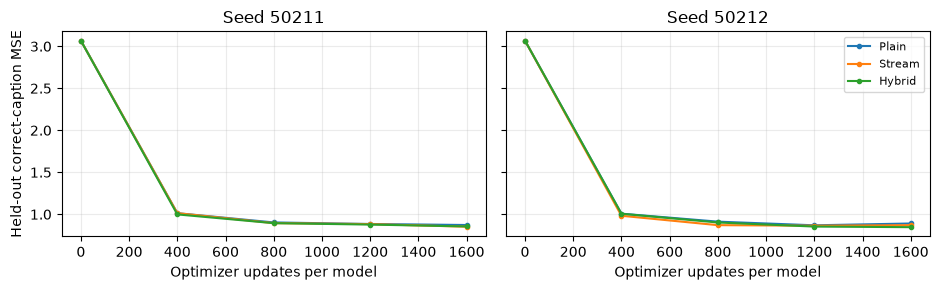

In [6]:
kinds = ("Plain", "Stream", "Hybrid")
seeds = (50211, 50212)
checkpoints = (0, 400, 800, 1200, 1600)


def fresh(kind: str, seed: int) -> nn.Module:
    """复用前课两个基线；第三组使用相同接口的新教学主干。"""
    if kind != "Hybrid":
        return lesson["fresh_model"](kind, seed)
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        return HybridDiTReference()


trained, histories = {}, {}
elapsed = dict.fromkeys(kinds, 0.0)
for seed in seeds:
    models = {kind: fresh(kind, seed) for kind in kinds}
    opts = {
        kind: torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)
        for kind, model in models.items()
    }
    if seed == seeds[0]:
        for kind, model in models.items():
            count = sum(p.numel() for p in model.parameters() if p.requires_grad)
            print(f"{kind}: {count:,} trainable parameters")
    rng = torch.Generator().manual_seed(seed + 1000)
    history = {kind: [] for kind in kinds}
    for step in range(checkpoints[-1] + 1):
        if step in checkpoints:
            for kind, model in models.items():
                history[kind].append(validation_rows(model))
            means = " ".join(f"{kind}={history[kind][-1][:, 0].mean():.4f}" for kind in kinds)
            print(f"seed={seed} step={step:4d} right val {means}", flush=True)
        if step == checkpoints[-1]:
            break
        x, t, ids, target = step_batch(rng)
        for kind, model in models.items():
            started = perf_counter()
            opt = opts[kind]
            opt.zero_grad(set_to_none=True)
            loss = (velocity(model, x, t, text_bank[ids], mask_bank[ids]) - target).square().mean()
            if not torch.isfinite(loss):
                raise RuntimeError(f"{kind} had a nonfinite loss at step {step}")
            loss.backward()
            if step == 0:
                assert model.output.weight.grad.norm() > 0
            nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
            opt.step()
            elapsed[kind] += perf_counter() - started
    for kind, model in models.items():
        trained[seed, kind] = model.eval()
        histories[seed, kind] = history[kind]
print("CPU update wall time per configuration across both seeds (excludes probes and batch draw)")
print(" | ".join(f"{kind}: {elapsed[kind]:.1f}s" for kind in kinds))
print("seed | model  | right | wrong color | wrong shape | empty")
for (seed, kind), history in histories.items():
    print(f"{seed} | {kind:6} | " + " | ".join(f"{x:.5f}" for x in history[-1].mean(0)))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.0), sharey=True)
for ax, seed in zip(axes, seeds, strict=True):
    for kind in kinds:
        values = [row[:, 0].mean() for row in histories[seed, kind]]
        ax.plot(checkpoints, values, "o-", markersize=3, label=kind)
    ax.set(title=f"Seed {seed}", xlabel="Optimizer updates per model")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Held-out correct-caption MSE")
axes[-1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## **七、训练后核查｜看看图文信息是否真的通过**

### **1. 在同一个输入上单独改时间或掩码**

用第一个训练种子的 Hybrid 做干预。先只改 padding 内容，再追加三个无效槽，图像输出应在浮点误差内不变。单独改时间则应产生非零速度变化。把所有文本键设为无效是接口边界测试，和 CLIP 编码空字符串得到的两个有效特殊 token 含义不同。

探针以速度预测的平方均值为标量目标来反传。图像输入与有效文本的梯度应非零，无效文本的梯度应为零。双流图像、双流文本和共享单流各自检查整组参数的梯度范数，组内每个梯度张量都要有限，范数非零只要求组内有梯度可达。冻结组件保持无梯度。

分辨率探针把 64px 权重接到 256px 图像的潜变量和 77 个文本槽位上。取 $\epsilon=0$、$t=0.5$，所以这次输入是 $0.5z$。该前向只核对输出形状、有限性及非零响应。

In [7]:
hybrid = trained[seeds[0], "Hybrid"]
ids = torch.tensor([len(captions), 0])
features, valid = text_bank[ids], mask_bank[ids]
t = torch.tensor([0.2, 0.6])
noise = torch.randn(val_z[:2].shape, generator=torch.Generator().manual_seed(60171))
probe, _ = flow_example(val_z[:2], noise, t)
with torch.no_grad():
    base = velocity(hybrid, probe, t, features, valid)
    edited = torch.where(valid[..., None], features, 79.0)
    changed = velocity(hybrid, probe, t, edited, valid)
    extra_text = torch.cat((features, torch.full_like(features[:, :3], -55.0)), dim=1)
    extra_valid = torch.cat((valid, torch.zeros_like(valid[:, :3])), dim=1)
    extended = velocity(hybrid, probe, t, extra_text, extra_valid)
    torch.testing.assert_close(base, changed, rtol=1e-5, atol=3e-6)
    torch.testing.assert_close(base, extended, rtol=1e-5, atol=3e-6)
    print(f"Hybrid padded-input max change: {(base - extended).abs().max():.3g}")
    time_change = (base - velocity(hybrid, probe, t + 0.15, features, valid)).square().mean().sqrt()
    assert time_change > 1e-3
    print(f"Hybrid time-only velocity RMS delta: {time_change:.5f}")
    no_text = torch.zeros_like(valid)
    image_only = velocity(hybrid, probe, t, features, no_text)
    assert torch.isfinite(image_only).all()
    torch.testing.assert_close(image_only, velocity(hybrid, probe, t, -features, no_text))

    large_clean = prev["z_256"]
    large_t = torch.tensor([0.5])
    large_z, _ = flow_example(large_clean, torch.zeros_like(large_clean), large_t)
    large = velocity(hybrid, large_z, large_t, prev["text_full"][:1], prev["mask_full"][:1])
    assert large.shape == (1, 4, 32, 32) and torch.isfinite(large).all()
    assert large.abs().max() > 1e-5
    print(f"Trained Hybrid 256px: {tuple(large.shape)}, finite, nonzero")

z_leaf = probe.detach().clone().requires_grad_()
text_leaf = features.detach().clone().requires_grad_()
gradient_groups = {
    "dual image": tuple(hybrid.dual_blocks[0].image.parameters()),
    "dual text": tuple(hybrid.dual_blocks[0].caption.parameters()),
    "single": tuple(hybrid.single_blocks[0].parameters()),
}
score = velocity(hybrid, z_leaf, t, text_leaf, valid).square().mean()
flat = tuple(p for group in gradient_groups.values() for p in group)
grad_z, grad_text, *grad_weights = torch.autograd.grad(score, (z_leaf, text_leaf, *flat))
assert all(torch.isfinite(g).all() for g in (grad_z, grad_text, *grad_weights))
assert grad_z.norm() > 0 and grad_text[valid].norm() > 0
assert torch.count_nonzero(grad_text[~valid]) == 0
print(f"Input gradients: latent={grad_z.norm():.5f}, valid text={grad_text[valid].norm():.5f}")
offset = 0
for name, group in gradient_groups.items():
    grads = grad_weights[offset : offset + len(group)]
    norm = torch.stack([g.square().sum() for g in grads]).sum().sqrt()
    assert norm > 0
    print(f"Weight gradient {name}: {norm:.5f}")
    offset += len(group)
assert all(
    p.grad is None
    for component in (vae.model, prev["text_encoder"].model)
    for p in component.parameters()
)

Hybrid padded-input max change: 1.73e-06
Hybrid time-only velocity RMS delta: 0.38991
Trained Hybrid 256px: (1, 4, 32, 32), finite, nonzero
Input gradients: latent=0.18937, valid text=0.05299
Weight gradient dual image: 8.01876
Weight gradient dual text: 1.86394
Weight gradient single: 5.85726


### **2. 可视化四个象限**

取第一个双流块、一个训练后的模型和一例空字符串探针。用该块真实 Q/K 显式计算权重，验证每条概率行和为 1、padding 键权重为零，并对照加权值结果与 SDPA 一致。图画的是头平均概率，橙线标记文本与图像边界。无效查询行留白，因此 **整列零值** 与 **整行留白** 分别表示键遮罩与查询的展示处理。

右上象限每行求和，可得到某条有效文本查询从图像键分到的权重；左下同理。图像有 16 个键，而这个空条件只有两个有效文本键，跨区总权重同时受键数和打分影响。若每个合法键都拿到相同分数，两个跨区的均匀读取基线分别为 $16/18$ 和 $2/18$。因此两方向总权重不能直接比较；热图的行列是 query 指向 key，而被读取的 V 信息从键所在位置流向查询位置。它只展示一层、一个输入和一次时间点，也没有计入 $V$、输出投影或后续残差，不能当作语义归因。

T→I mean total attention mass: 0.7680
I→T mean total attention mass: 0.3448


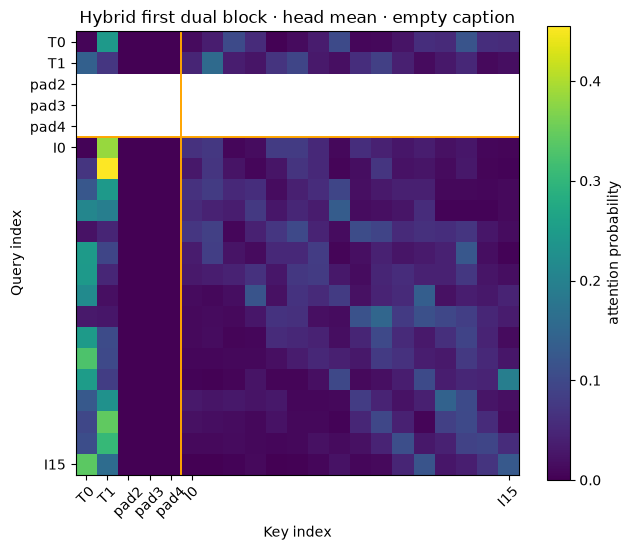

In [8]:
@torch.no_grad()
def inspect_joint_weights() -> None:
    """显式取回第一双流块各头的打分，以无效文本槽为掩码探针。"""
    img, txt, e, coords = hybrid.prepare(probe[:1], t[:1] * 1000, features[:1], valid[:1])
    block = hybrid.dual_blocks[0]
    packed_text, _ = block.caption.project(txt, e)
    packed_image, _ = block.image.project(img, e)
    mask = joint_valid(valid[:1], img)[0]
    nt = txt.shape[1]
    q, k, v = joint_qkv(torch.cat((packed_text, packed_image), dim=1), block.heads, nt, coords)
    logits = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1])
    weights = logits.masked_fill(~mask, -torch.inf).softmax(-1)
    torch.testing.assert_close(weights.sum(-1), torch.ones_like(weights[..., 0]))
    assert torch.count_nonzero(weights[..., ~mask]) == 0
    manual = (weights @ v).transpose(1, 2).flatten(2)
    fused = joint_attention(
        torch.cat((packed_text, packed_image), dim=1), block.heads, nt, coords, mask[None]
    )
    torch.testing.assert_close(manual, fused, rtol=1e-5, atol=2e-6)

    # 无效查询行仅用于标记边界，在图上留白。
    matrix = weights[0].mean(0).masked_fill(~mask[:, None], torch.nan)
    print(f"T→I mean total attention mass: {matrix[:nt, nt:].sum(-1)[mask[:nt]].mean():.4f}")
    print(f"I→T mean total attention mass: {matrix[nt:, :nt].sum(-1).mean():.4f}")
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    image = ax.imshow(matrix, interpolation="nearest", cmap="viridis", vmin=0)
    for draw in (ax.axvline, ax.axhline):
        draw(nt - 0.5, color="orange", linewidth=1.4)
    labels = [*(f"T{i}" if keep else f"pad{i}" for i, keep in enumerate(mask[:nt])), "I0", "I15"]
    ticks = [*range(nt), nt, len(mask) - 1]
    ax.set(
        title="Hybrid first dual block · head mean · empty caption",
        xlabel="Key index",
        ylabel="Query index",
        xticks=ticks,
        yticks=ticks,
        xticklabels=labels,
        yticklabels=labels,
    )
    ax.tick_params(axis="x", labelrotation=45)
    fig.colorbar(image, ax=ax, label="attention probability")
    fig.tight_layout()
    plt.show()


inspect_joint_weights()

## **八、同 NFE 采样｜把速度误差与生成表现分开**

固定 Euler 20 步，每步仅计算有条件速度，CFG 取 1。三配置共享四条提示、每条四份固定起始噪声，同一份噪声跨提示复用便于并排观察。六次训练各生成 16 张，总计 96 张。两张图库按训练种子拆分，行对应提示、列对应模型和起始噪声种子。

规则解析器在留出原图与其 VAE 重建上先做核对，然后按相同阈值评估生成图。联合命中要求颜色、形状都对；无法解析计入总分母并单报。命中数是这套简单图形规则的结果，不能代替画质或真实复杂提示的评估。

held-out original: color=32/32, shape=32/32, both=32/32, unparsed=0/32


held-out VAE recon: color=32/32, shape=32/32, both=32/32, unparsed=0/32


50211 Plain  | Euler 20 NFE | color=14/16, shape=6/16, both=6/16, unparsed=2/16


50211 Stream | Euler 20 NFE | color=12/16, shape=6/16, both=6/16, unparsed=4/16


50211 Hybrid | Euler 20 NFE | color=16/16, shape=8/16, both=8/16, unparsed=0/16


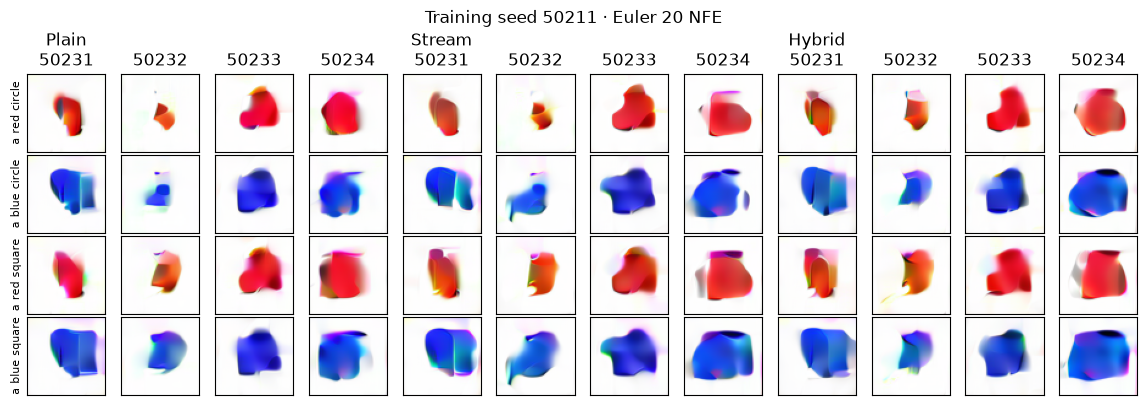

50212 Plain  | Euler 20 NFE | color=13/16, shape=6/16, both=6/16, unparsed=3/16


50212 Stream | Euler 20 NFE | color=12/16, shape=5/16, both=5/16, unparsed=4/16


50212 Hybrid | Euler 20 NFE | color=13/16, shape=5/16, both=5/16, unparsed=3/16


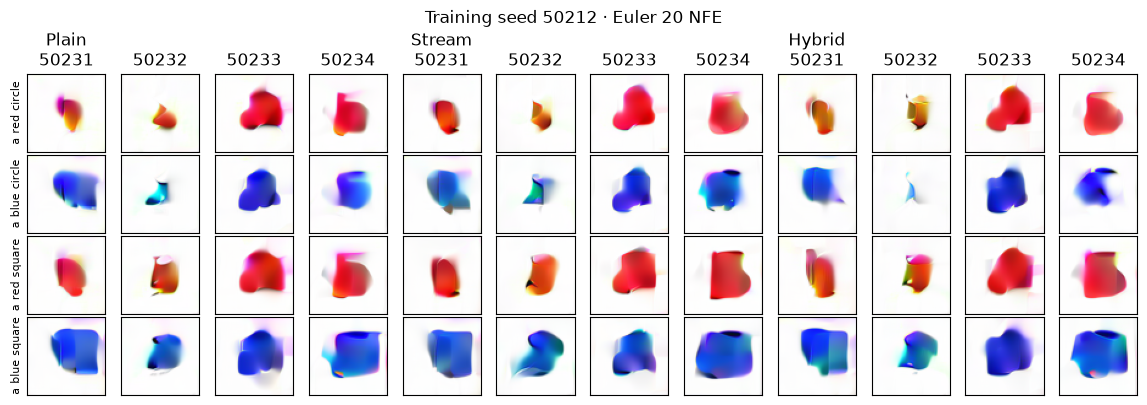

In [9]:
@torch.no_grad()
def compare_samples() -> None:
    """以配对起始噪声对三套模型配置采样，并保留完整图库。"""
    decode = vae.decode
    score_icons = prev["report_scores"]
    sample = prev["sample_reference"]
    print("held-out original:", score_icons(prev["val_x"], val_y))
    print("held-out VAE recon:", score_icons(torch.cat([decode(x) for x in val_z.split(8)]), val_y))
    sample_seeds = (50231, 50232, 50233, 50234)
    starts = torch.cat(
        [
            torch.randn((1, 4, 8, 8), generator=torch.Generator().manual_seed(s))
            for s in sample_seeds
        ]
    ).repeat((len(captions), 1, 1, 1))
    prompt_ids = torch.arange(len(captions)).repeat_interleave(len(sample_seeds))
    for seed in seeds:
        fig, axes = plt.subplots(len(captions), 12, figsize=(11.5, 4.0))
        for group, kind in enumerate(kinds):
            endpoint, counts = sample(
                trained[seed, kind], starts, prompt_ids, 20, heun=False, scale=1
            )
            assert counts == (20, 20, 20)
            images = torch.cat([decode(x) for x in endpoint.split(8)])
            assert torch.isfinite(images).all()
            print(f"{seed} {kind:6} | Euler 20 NFE | {score_icons(images, prompt_ids)}")
            for row, caption in enumerate(captions):
                for col, sample_seed in enumerate(sample_seeds):
                    ax = axes[row, group * len(sample_seeds) + col]
                    rgb = (images[row * len(sample_seeds) + col].permute(1, 2, 0) + 1) / 2
                    ax.imshow(rgb.clamp(0, 1))
                    ax.set_xticks([])
                    ax.set_yticks([])
                    if row == 0:
                        ax.set_title(f"{kind}\n{sample_seed}" if col == 0 else str(sample_seed))
                    if group == col == 0:
                        ax.set_ylabel(caption, fontsize=8)
        fig.suptitle(f"Training seed {seed} · Euler 20 NFE")
        fig.tight_layout(pad=0.5)
        plt.show()


compare_samples()

### **1. 读这张表时，保留种子这一列**

| 训练种子 | 配置 | 正确条件 MSE | 颜色 | 形状 | 联合命中 | 无法解析 |
| --- | --- | --- | --- | --- | --- | --- |
| 50211 | Plain | 0.87247 | 14/16 | 6/16 | 6/16 | 2/16 |
| 50211 | Stream | 0.85246 | 12/16 | 6/16 | 6/16 | 4/16 |
| 50211 | Hybrid | 0.85537 | 16/16 | 8/16 | 8/16 | 0/16 |
| 50212 | Plain | 0.89049 | 13/16 | 6/16 | 6/16 | 3/16 |
| 50212 | Stream | 0.87049 | 12/16 | 5/16 | 5/16 | 4/16 |
| 50212 | Hybrid | 0.84671 | 13/16 | 5/16 | 5/16 | 3/16 |

三组初始速度为零，留出 MSE 均为 3.0672。训练后，六个实例都对正确条件取得比错颜色、错形状与空条件更低的 MSE。颜色干预带来的误差差异大于形状干预，图库也显示颜色普遍更容易做对。速度误差对每个潜变量元素取平均，不能从差异大小直接推断模型对两种属性的理解程度。

Hybrid 的留出 MSE 两次都低于 Plain，与 Stream 的排序随种子变化。采样看到了更明显的波动：Hybrid 在 50211 上得到 8/16 个联合命中，在 50212 上变成 5/16，后者低于 Plain 且与 Stream 持平。看第二张图库中 Hybrid 的蓝圆、起始噪声 50232：只留下很淡的蓝色碎块，与完整圆形相差很远。留出原图和重建均为 32/32 联合命中，说明该规则能解析这批真实几何与 VAE 重建，生成图上的异常仍可能超出规则可靠范围。

### **2. 证据的尺度**

三组实测可训练参数为 609,714、645,856、609,316。Hybrid 与 Plain 只差 398 个参数，但位置编码、头宽与注意力路由等因素也有变化。参数近似相等有助于缩小差异，不能把生成排名的变化独立归因给双流。两种子和四份复用噪声也不足以估计稳定的优势。等更新次数表示看过同样多的配对输入；等 NFE 表示同样多的速度求值。每次更新或求值的成本仍依赖模型配置。上文 CPU 计时只覆盖这次本机短训的更新开销。

本课验证了双流确实可双向交换信息，合流和潜变量输出接线正确，三套配置都能用同一个接口训练并采样。正式模型的画质、复杂文本遵循和训练效率属于后续实验。

## **九、自己实现两处，再进入 S7**

### **1. 练习与可运行验收**

先写 `DoubleStreamBlock.forward`：用两个分支各自产生 QKV 和调制参数，拼接一次联合注意力，再按查询边界分开更新。再写 `HybridDiT.forward`：保持图文状态直到双流阶段结束，拼接给并行单流、裁出图像后缀、用速度头和逆 patch 收尾。个人模型使用个人双流块，已有的并行单流层可以复用。

写完重跑下方单元。双流的验收使用两支开启门的显式算例，整网验收检查路由。两处完成后可显式把个人模型传入 `velocity` 做新短跑。

In [10]:
class DoubleStreamBlock(DoubleStreamBlockReference):
    """练习一，写双流的联合注意力与两个模态的残差接线。"""

    def forward(
        self, image: Tensor, caption: Tensor, time: Tensor, text_valid: Tensor, coords: Tensor
    ) -> tuple[Tensor, Tensor]:
        raise NotImplementedError("DoubleStreamBlock.forward")


class HybridDiT(HybridDiTReference):
    """练习二，将你的双流块接到共享的合流块与图像输出头。"""

    double_block_type = DoubleStreamBlock

    def forward(self, z: Tensor, feature_time: Tensor, text: Tensor, text_valid: Tensor) -> Tensor:
        raise NotImplementedError("HybridDiT.forward")


assert isinstance(HybridDiT().dual_blocks[0], DoubleStreamBlock)
for learner, check in ((DoubleStreamBlock, audit_double_stream), (HybridDiT, audit_hybrid_routing)):
    try:
        check(learner)
    except NotImplementedError as exc:
        if str(exc) != f"{learner.__name__}.forward":
            raise
        print(f"{learner.__name__}.forward 待完成")
    else:
        print(f"{learner.__name__}.forward 通过")

DoubleStreamBlock.forward 待完成
HybridDiT.forward 待完成


### **2. 四个可以用来复述本课的问题**

<details>
<summary>问：双流在拼接成共享序列之前，图像损失已经能更新文本参数吗？</summary>

可以。图像查询的联合 softmax 含有效文本键，输出也包含文本 V 的加权值。图像损失沿这条链直接回传给文本 K/V 投影。文本查询也会读取图像 K/V。要把图像损失回传到文本 Q、输出投影和 MLP，还需要下游图像路径继续读取更新后的文本状态。只有残差门关闭、掩码切断或退化输入等情况才会使特定路径失去梯度。

</details>

<details>
<summary>问：调制后的输入宽度是 100，为什么并行块先输出 700，再输入 500？</summary>

700 是三份 100 维的 Q/K/V 与 400 维 MLP 中间量。Q/K/V 经联合注意力后合成一份 100 维输出，再与激活后的 400 维 MLP 特征沿特征轴拼接，得到 500 维。沿 token 轴的图文顺序不变。

</details>

<details>
<summary>问：照着混元写图像切片，为什么这里可能反而切错？</summary>

混元先放图像，因此取图像前缀。教学版延续 S5-02 的文本在前，所以取后缀。拼接、RoPE 区间、mask、拆流和输出必须遵循同一顺序。实际边界由张量槽位数确定。

</details>

<details>
<summary>问：想知道提升来自独立模态参数，下一次只改变哪一项？</summary>

先固定宽度、头数、RoPE、每层可见性和残差计算顺序，把同一个串行联合块中的图文权重由共享改成两套，观察拆分参数的影响。此时参数量会改变，需要如实报告。若目标改为比较给定计算预算下的系统效果，再匹配总 FLOPs 或训练时间，允许配置不同。两种实验回答的问题不同。

</details>

下一课 S7-01 会把这三种速度接口接到正式的公平实验设计上。需要事先确定参数预算、实际计算预算、样本暴露量和重复次数，并保留失败例与不同指标排序不一致的情况。